### **Summary**

Lagrangian Neural Networks (LNNs) harness the expressive power of neural networks to learn arbitrary Lagrangians from data. In contrast to Hamiltonian Neural Networks, these models do not require canonical coordinates and perform well in situations where generalized momentum is difficult to compute (eg the double pendulum). This is particularly appealing for use with a learned latent representation, though this application is a work in progress. Unlike previous work on learning Lagrangians, LNNs can learn arbitrary Lagrangians.

### **Lagrangians**

Following David Morin's excellent introduction to Lagrangians, we define the Lagrangian as a scalar function $\mathcal{L} \equiv T - U$ with $T$ and $U$ as kinetic and potential energies, respectively. It turns out that we can obtain the equations of motion of an arbitrary physical system using the relationship

\begin{equation*}
\frac{d}{dt}\frac{\partial\mathcal{L}}{\partial\dot{q}_j} = \frac{\partial\mathcal{L}}{\partial q_j}
\end{equation*}

We call this the *Euler-Lagrange (E-L) equation* and we obtain it by requiring that the quantity

\begin{equation*}
S \equiv \int_{t_1}^{t_2} \mathcal{L}(q, \dot{q}, t) \ dt
\end{equation*}

have a stationary value. In other words, we require that $S$ be at a local minimum, maximum, or saddle point. We call $S$ the "action" of the system, so the E-L relationship is a mathematical tool for describing its "path of stationary action". One way to think of $S$ is as the cost function that Nature minimizes in order to give us the dynamics of the natural world.

## **Step 1: Basic imports**
We will implement this project in JAX.

*Note: getting this version of Jax to find the GPU is a little iffy, and yet we need its version of the `odeint` function. Our workaround is to run the following cell, restart the Colab runtime (but don't do "Factory reset runtime"), and then run the next cell.*

In [1]:
import jax
import jax.numpy as jnp
import numpy as np
from jax.experimental.ode import odeint
import matplotlib.pyplot as plt
from functools import partial # reduces arguments to function by making some subset implicit

# from jax.experimental import stax
# from jax.experimental import optimizers
# Modern JAX compatibility
from jax.example_libraries import stax
from jax.example_libraries import optimizers

# visualization
from matplotlib.patches import Circle
# from moviepy.editor import ImageSequenceClip
# import proglog
from PIL import Image

### **Optional: Using the LNN Package**

This notebook is self-contained, but you can also use the `lnn` package if it's installed:

```
# If you have the lnn package installed:
from lnn import (
    lagrangian_eom,
    solve_dynamics,
    mlp,
    wrap_coords
)
from examples.double_pendulum.physics import lagrangian_fn
from examples.double_pendulum.data import get_dataset
```

In [2]:
# Check if lnn package is available
try:
    import lnn
    print(f"✓ LNN package version {lnn.__version__} is available")
    HAS_LNN = True
except ImportError:
    print("ℹ️ LNN package not found. This notebook will use its self-contained implementations.")
    HAS_LNN = False

ℹ️ LNN package not found. This notebook will use its self-contained implementations.


### Make sure we're using a GPU

In [3]:
# from jax.lib import xla_bridge
# print(xla_bridge.get_backend().platform)

# Modern JAX compatibility
print(jax.default_backend())

cpu


## **Step 2: Model the Double Spherical Pendulum**
The Lagrangian of the double spherical pendulum is

\begin{align*}
\mathcal{L} &= \frac{1}{2}(m_1 + m_2)R_1^2(\dot{\theta}_1^2 + \dot{\phi}_1^2\sin^2\theta_1) + \frac{1}{2}m_2\Big\{ 2R_1R_2\Big[\dot{\theta}_1\dot{\theta}_2\big(\cos\theta_1\cos\theta_2\cos(\phi_1 - \phi_2) + \sin\theta_1\sin\theta_2\big) \\
    &\qquad + \dot{\theta}_1\dot{\phi}_2\cos\theta_1\sin\theta_2\sin(\phi_1 - \phi_2) + \dot{\phi}_1\dot{\theta}_2\sin\theta_1\cos\theta_2\sin(\phi_2 - \phi_1) + \dot{\phi}_1\dot{\phi}_2\sin\theta_1\sin\theta_2\cos(\phi_1 - \phi_2) \Big] \\
    &\qquad + R_2^2(\dot{\theta}_2^2 + \dot{\phi}_2^2\sin^2\theta_2) \Big\} + (m_1 + m_2)gR_1\cos\theta_1 + m_2gR_2\cos\theta_2
\end{align*}

In [4]:
def lagrangian(q, q_dot, m1, m2, R1, R2, g):
    t1, t2, p1, p2 = q         # theta 1, theta 2, phi 1, phi 2
    t1d, t2d, p1d, p2d = q_dot # theta 1 dot, theta 2 dot, phi 1 dot, phi 2 dot

    # kinetic energy (T)
    T1 = 0.5 * m1 * R1**2 * (t1d**2 + p1d**2 * jnp.sin(t1)**2) 
    T2 = 0.5 * m2 * R1**2 * (t1d**2 + p1d**2 * jnp.sin(t1)**2) + 0.5 * m2 * (2 * R1 * R2 * (t1d * t2d * (jnp.cos(t1) * jnp.cos(t2) * jnp.cos(p1 - p2) + jnp.sin(t1) * jnp.sin(t2)) + t1d * p2d * jnp.cos(t1) * jnp.sin(t2) * jnp.sin(p1 - p2) + p1d * t2d * jnp.sin(t1) * jnp.cos(t2) * jnp.sin(p2 - p1) + p1d * p2d * jnp.sin(t1) * jnp.sin(t2) * jnp.cos(p1 - p2)) + R2**2 * (t2d**2 + p2d**2 * jnp.sin(t2)**2))
    T = T1 + T2

    # potential energy (U)
    z1 = R1 * jnp.cos(t1)
    z2 = z1 + R2 * jnp.cos(t2)
    U = -m1 * g * z1 - m2 * g * z2

    return T - U

We'll want to check our results against an analytical solution. We can express the analytical dynamics of the system in matrix form:

\begin{align*}
\dfrac{d}{dt}
\begin{pmatrix}
\theta_1 \\
\theta_2 \\
\phi_1 \\
\phi_2 \\
\dot{\theta}_1 \\
\dot{\theta}_2 \\
\dot{\phi}_1 \\
\dot{\phi}_2 
\end{pmatrix}
&= 
\begin{pmatrix}
\dot{\theta}_1 \\
\dot{\theta}_2 \\
\dot{\phi}_1 \\
\dot{\phi}_2 \\
\ddot{\theta}_1 \\
\ddot{\theta}_2 \\
\ddot{\phi}_1 \\
\ddot{\phi}_2
\end{pmatrix}
\end{align*}

In [5]:
import sympy as sp

# Defining symbols
t, g = sp.symbols('t g')
m1, m2 = sp.symbols('m1 m2')
R1, R2 = sp.symbols('R1 R2')

# Defining functions
theta1, theta2, phi1, phi2 = sp.symbols(r'\theta_1, \theta_2, \phi_1, \phi_2', cls=sp.Function)

theta1 = theta1(t)
theta2 = theta2(t)
phi1 = phi1(t)
phi2 = phi2(t)

theta1_dot = sp.diff(theta1, t)
theta2_dot = sp.diff(theta2, t)
phi1_dot = sp.diff(phi1, t)
phi2_dot = sp.diff(phi2, t)
theta1_ddot = sp.diff(theta1_dot, t)
theta2_ddot = sp.diff(theta2_dot, t)
phi1_ddot = sp.diff(phi1_dot, t)
phi2_ddot = sp.diff(phi2_dot, t)

x1 = R1 * sp.sin(theta1) * sp.cos(phi1)
y1 = R1 * sp.sin(theta1) * sp.sin(phi1)
z1 = R1 * sp.cos(theta1)
x2 = x1 + R2 * sp.sin(theta2) * sp.cos(phi2)
y2 = y1 + R2 * sp.sin(theta2) * sp.sin(phi2)
z2 = z1 + R2 * sp.cos(theta2)

T1 = sp.Rational(1, 2) * m1 * (sp.diff(x1, t)**2 + sp.diff(y1, t)**2 + sp.diff(z1, t)**2)
T2 = sp.Rational(1, 2) * m2 * (sp.diff(x2, t)**2 + sp.diff(y2, t)**2 + sp.diff(z2, t)**2)
T = T1 + T2

U1 = -m1 * g * z1
U2 = -m2 * g * z2
U = U1 + U2

L = T - U

EL1 = (sp.diff(sp.diff(L, theta1_dot), t) - sp.diff(L, theta1)).simplify()
EL2 = (sp.diff(sp.diff(L, theta2_dot), t) - sp.diff(L, theta2)).simplify()
EL3 = (sp.diff(sp.diff(L, phi1_dot), t) - sp.diff(L, phi1)).simplify()
EL4 = (sp.diff(sp.diff(L, phi2_dot), t) - sp.diff(L, phi2)).simplify()

M, F = sp.linear_eq_to_matrix([EL1, EL2, EL3, EL4], [theta1_ddot, theta2_ddot, phi1_ddot, phi2_ddot])
accel = M.LUsolve(F)

sols = {
    theta1_ddot: accel[0],
    theta2_ddot: accel[1],
    phi1_ddot: accel[2],
    phi2_ddot: accel[3],
}

In [6]:
t1, t2, p1, p2 = sp.symbols('t1 t2 p1 p2')
t1d, t2d, p1d, p2d = sp.symbols('t1d t2d p1d p2d')

subs_num = {
    theta1: t1,
    theta2: t2,
    phi1: p1,
    phi2: p2,
    theta1_dot: t1d,
    theta2_dot: t2d,
    phi1_dot: p1d,
    phi2_dot: p2d,
}

M_num = M.subs(subs_num)
F_num = F.subs(subs_num)

jax_modules = {
    'sin': jnp.sin,
    'cos': jnp.cos,
    'sqrt': jnp.sqrt,
    'ImmutableDenseMatrix': jnp.array
}

M_func = sp.lambdify(
    (t1, t2, p1, p2, t1d, t2d, p1d, p2d, m1, m2, R1, R2, g),
    M_num, 
    modules=[jax_modules]
)

F_func = sp.lambdify(
    (t1, t2, p1, p2, t1d, t2d, p1d, p2d, m1, m2, R1, R2, g),
    F_num,
    modules=[jax_modules]
)

In [7]:
def f_analytical(state, t=0, m1=1, m2=1, R1=1, R2=1, g=9.8):
    t1, t2, p1, p2, t1d, t2d, p1d, p2d = state

    args = (
        t1, t2, p1, p2,
        t1d, t2d, p1d, p2d,
        m1, m2, R1, R2, g
    )

    M_eval = jnp.asarray(M_func(*args))
    F_eval = jnp.asarray(F_func(*args)).reshape(4)

    qdd = jnp.linalg.solve(M_eval, F_eval)

    return jnp.stack([
        t1d, t2d, p1d, p2d,
        qdd[0], qdd[1], qdd[2], qdd[3]
    ])

## **Step 3: Obtain dynamics from the Lagrangian**

We have written our Lagrangian and now we want to use it to obtain the dynamics of the system. Physicists would ordinarily try applying the Euler-Lagrange relationship in order to compute a set of analytical equations of motion. In this situation, though, our Lagrangian is a neural network. Trying to get an analytic solution from a neural network Lagrangian would be like trying to knit with a plate of spaghetti.

A better idea is to obtain the dynamics through numerical integration, and to do this we'll need an expression for $\ddot{q}$. Let's begin with the E-L constraint and try to solve for $\ddot{q}$.

\begin{align}
\frac{d}{dt}\frac{\partial\mathcal{L}}{\partial\dot{q}_j} &= \frac{\partial\mathcal{L}}{\partial q_j} &\qquad \text{write down the Euler-Lagrange equation} \\
\frac{d}{dt}\nabla_{\dot{q}}\mathcal{L} &= \nabla_q \mathcal{L} &\qquad \text{switch to vector notation} \\
(\nabla_{\dot{q}}\nabla_{\dot{q}}^T\mathcal{L})\ddot{q} + (\nabla_q\nabla_{\dot{q}}^T\mathcal{L})\dot{q} &= \nabla_q \mathcal{L} &\qquad \text{expand the time derivative $\dfrac{d}{dt}$} \\
\ddot{q} &= (\nabla_{\dot{q}}\nabla_{\dot{q}}^T\mathcal{L})^{-1}[\nabla_q \mathcal{L} - (\nabla_q \nabla_{\dot{q}}^T \mathcal{L})\dot{q}] &\qquad \text{use a matrix inverse to solve for $\ddot{q}$}
\end{align}

**Implementation.** If you look closely at Equation 4, you may noticce that it involves both the Hessian and the gradient of a neural network during the forward pass of the LNN. This is not a trivial operation, but modern automatic differentiation makes things surprisingly smooth. Written in JAX, Equation 4 is just a few lines of code

```
q_tt = (jnp.linalg.pinv(jax.hessian(lagrangian, 1)(q, q_t)) @
        (jax.grad(lagrangian, 0)(q, q_t)
        - jax.jacobian(jax.jacobian(lagrangian, 1), 0)(q, q_t) * q_t))
```

In order to get the full dynamics, we also have to integrate the equation of motion (JAX makes this easy with `odeint`).

In [8]:
def equation_of_motion(lagrangian, state, t=None):
    q, q_t = jnp.split(state, 2)
    q_tt = (jnp.linalg.pinv(jax.hessian(lagrangian, 1)(q, q_t))
            @ (jax.grad(lagrangian, 0)(q, q_t)
               - jax.jacobian(jax.jacobian(lagrangian, 1), 0)(q, q_t) @ q_t))
    return jnp.concatenate([q_t, q_tt])

def solve_lagrangian(lagrangian, initial_state, **kwargs):
    # We currently run odeint on CPUs only, because its cost is dominated by
    # control flow, which is slow on GPUs.
    @partial(jax.jit, backend='cpu')
    def f(initial_state):
        return odeint(partial(equation_of_motion, lagrangian),
                      initial_state, **kwargs)
    return f(initial_state)

### **Helper functions**

Here are a few useful helper functions for obtaining dynamics of the system.

In [9]:
# Double spherical pendulum dynamics via the rewritten Euler-Lagrange
@partial(jax.jit, backend='cpu')
def solve_autograd(initial_state, times ,m1=1, m2=1, R1=1, R2=1, g=9.8):
    L = partial(lagrangian, m1=m1, m2=m2, R1=R1, R2=R2, g=g)
    return solve_lagrangian(L, initial_state, t=times, rtol=1e-10, atol=1e-10)

# Double spherical pendulum dynamics via analytical forces
@partial(jax.jit, backend='cpu')
def solve_analytical(initial_state, times):
    return odeint(f_analytical, initial_state, t=times, rtol=1e-10, atol=1e-10)

def normalize_dp(state):
    # wrap generalized coordinates to [-pi, pi]
    return jnp.concatenate([(state[:4] + np.pi) % (2 * np.pi) - np.pi, state[4:]])

def rk4_step(f, x, t, h):
    # one step of runge-kutta integration
    k1 = h * f(x, t)
    k2 = h * f(x + k1/2, t + h/2)
    k3 = h * f(x + k2/2, t + h/2)
    k4 = h * f(x + k3, t + h)
    return x + 1/6 * (k1 + 2 * k2 + 2 * k3 + k4)

C:\Users\<user>\AppData\Local\Temp\ipykernel_27932\546093326.py:2: DeprecationWarning: backend and device argument on jit is deprecated. You can use `jax.device_put(..., jax.local_devices(backend="cpu")[0])` on the inputs to the jitted function to get the same behavior.
  @partial(jax.jit, backend='cpu')
C:\Users\<user>\AppData\Local\Temp\ipykernel_27932\546093326.py:8: DeprecationWarning: backend and device argument on jit is deprecated. You can use `jax.device_put(..., jax.local_devices(backend="cpu")[0])` on the inputs to the jitted function to get the same behavior.
  @partial(jax.jit, backend='cpu')


## **Step 4: Compare Autograd vs. Analytic solutions**

Having rewritten the Euler-Lagrange equations so that we can use automatic differnetiation to obtain the dynamics of the system, it's time to make sure that this approach matches the analytic solution. Here, we'll choose a random initial state and obtain dynamics via both "autograd" and "analytic" approaches. Then we'll slightly perturb the analytic solution to measure how sensitive it is to initial conditions. Taken together, these measurements should give us an approximate idea of whether our autograd-based approach is doing something reasonable.

In [10]:
# choose an initial state
x0 = np.array([3*np.pi/7, 3*np.pi/7, 3*np.pi/4, 3*np.pi/4, 0, 0, 0, 0], dtype=np.float32)
noise = np.random.RandomState(0).randn(x0.size)
t = np.linspace(0, 40, num=401, dtype=np.float32)

In [11]:
# compute dynamics analytically
%time x_analytical = jax.device_get(solve_analytical(x0, t))
noise_coeff_1, noise_coeff_2 = 1e-10, 1e-11
x_perturbed_1 = jax.device_get(solve_analytical(x0 + noise_coeff_1 * noise, t))
x_perturbed_2 = jax.device_get(solve_analytical(x0 + noise_coeff_2 * noise, t))

CPU times: total: 1.88 s
Wall time: 2.65 s


In [12]:
# compute dynamics via autograd / the rewritten E-L equation
%time x_autograd = jax.device_get(solve_autograd(x0, t))

C:\Users\<user>\AppData\Local\Temp\ipykernel_27932\370698877.py:11: DeprecationWarning: backend and device argument on jit is deprecated. You can use `jax.device_put(..., jax.local_devices(backend="cpu")[0])` on the inputs to the jitted function to get the same behavior.
  @partial(jax.jit, backend='cpu')


CPU times: total: 3.77 s
Wall time: 2.7 s


**Plot a comparison**

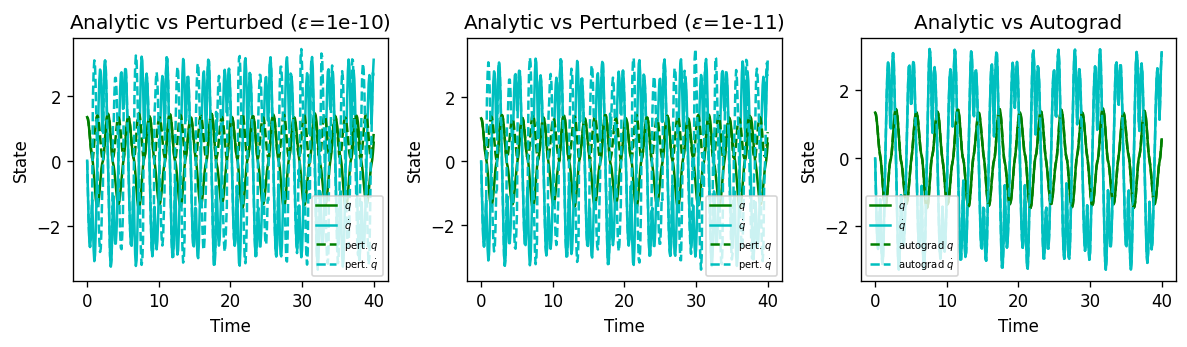

In [13]:
plt.figure(figsize=[10,3], dpi=120) ; # plt.xlim(0, 40)
plt.subplot(1,3,1)
plt.title(r"Analytic vs Perturbed ($\epsilon$={})".format(noise_coeff_1))
plt.xlabel("Time") ; plt.ylabel("State")
plt.plot(t, x_analytical[:, 0], 'g-', label=r'$q$')
plt.plot(t, x_analytical[:, 4], 'c-', label=r'$\dot{q}$')
plt.plot(t, x_perturbed_1[:, 0], 'g--', label=r'pert. $q$')
plt.plot(t, x_perturbed_1[:, 4], 'c--', label=r'pert. $\dot{q}$')
plt.legend(fontsize=6)

plt.subplot(1,3,2)
plt.title(r"Analytic vs Perturbed ($\epsilon$={})".format(noise_coeff_2))
plt.xlabel("Time") ; plt.ylabel("State")
plt.plot(t, x_analytical[:, 0], 'g-', label=r'$q$')
plt.plot(t, x_analytical[:, 4], 'c-', label=r'$\dot{q}$')
plt.plot(t, x_perturbed_2[:, 0], 'g--', label=r'pert. $q$')
plt.plot(t, x_perturbed_2[:, 4], 'c--', label=r'pert. $\dot{q}$')
plt.legend(fontsize=6)

plt.subplot(1,3,3)
plt.title("Analytic vs Autograd")
plt.xlabel("Time") ; plt.ylabel("State")
plt.plot(t, x_analytical[:, 0], 'g-', label=r'$q$')
plt.plot(t, x_analytical[:, 4], 'c-', label=r'$\dot{q}$')
plt.plot(t, x_autograd[:, 0], 'g--', label=r'autograd $q$')
plt.plot(t, x_autograd[:, 4], 'c--', label=r'autograd $\dot{q}$')
plt.legend(fontsize=6)

plt.tight_layout() ; plt.show()

## **Generate training data**

Let's generate some training data by using the analytical method to sample double spherical pendulum dynamics.

In [14]:
time_step = 0.01
N = 1500
T = 50.0
analytical_step = jax.jit(jax.vmap(partial(rk4_step, f_analytical, t=0.0, h=time_step)))

# x0 = np.array([-0.3*np.pi, 0.2*np.pi, 0.35*np.pi, 0.5*np.pi], dtype=float32)
x0 = np.array([3*np.pi/7, 3*np.pi/6, 3*np.pi/5, 3*np.pi/4, 0.1, 0.2, 0.3, 0.4], dtype=np.float32)
# t = np.arange(0.0, T, N, dtype=np.float32) # time steps 0 to N
t = np.linspace(0.0, T, N, dtype=np.float32) # 1500 sample times over [0, T]
%time x_train = jax.device_get(solve_analytical(x0, t)) # dynamics for first N time steps
%time xt_train = jax.device_get(jax.vmap(f_analytical)(x_train)) # time derivatives of each state
%time y_train = jax.device_get(analytical_step(x_train)) # analytical next step

x0_test = np.array([x0[0] + 0.05, x0[1] - 0.05, x0[2] + 0.05, x0[3] - 0.05, x0[4], x0[5], x0[6], x0[7]], dtype=np.float32)
noise = np.random.RandomState(0).randn(x0.size)
# t_test = np.arange(0.0, T, N, dtype=np.float32) # time steps N to 2N
t_test = np.linspace(0.0, T, N, dtype=np.float32) # 1500 sample times over [0, T]
%time x_test = jax.device_get(solve_analytical(x0_test, t_test)) # dynamics for next N time steps
%time xt_test = jax.device_get(jax.vmap(f_analytical)(x_test)) # time derivatives of each state
%time y_test = jax.device_get(analytical_step(x_test)) # analytical next step

CPU times: total: 3.23 s
Wall time: 2.5 s
CPU times: total: 1.45 s
Wall time: 1.02 s
CPU times: total: 1.31 s
Wall time: 641 ms
CPU times: total: 2.28 s
Wall time: 2.3 s
CPU times: total: 78.1 ms
Wall time: 54.6 ms
CPU times: total: 15.6 ms
Wall time: 5.58 ms


### **Visualize train and test data**

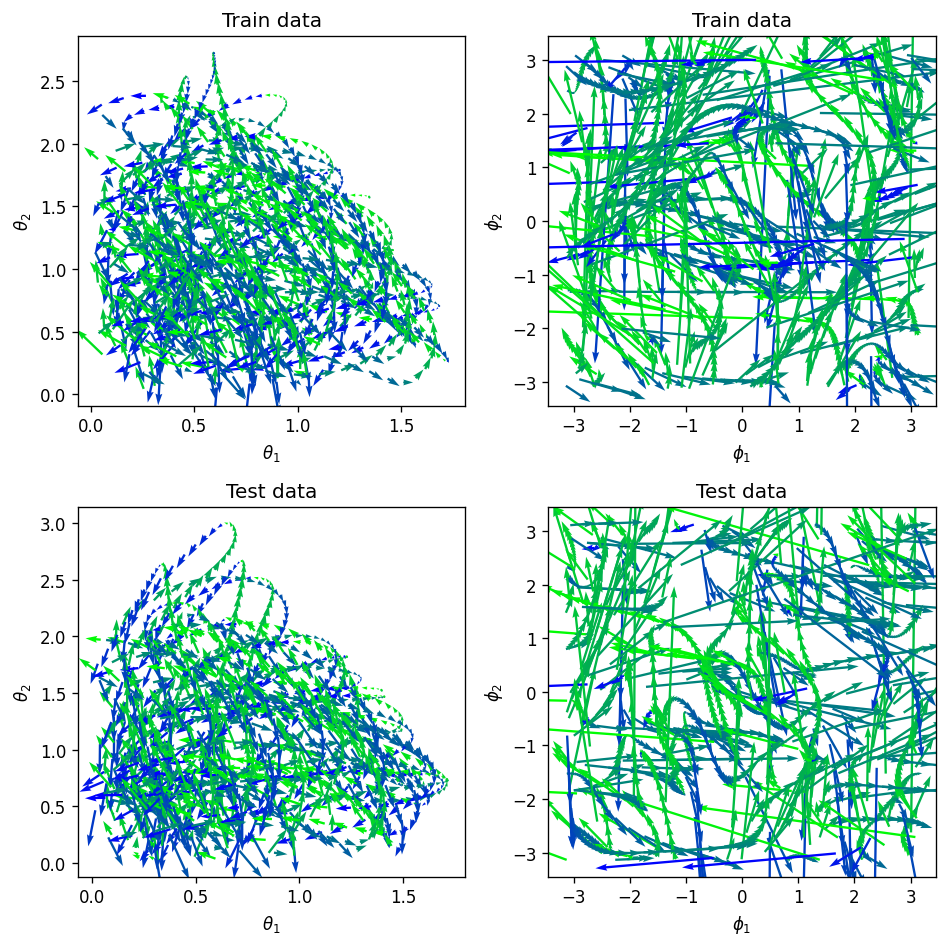

In [15]:
# preprocess
train_vis = jax.vmap(normalize_dp)(x_train)
test_vis = jax.vmap(normalize_dp)(x_test)

# vel_angle = lambda data: (np.arctan2(data[:,3], data[:,2]) / np.pi + 1)/2
def vel_angle(u, v):
    return (np.arctan2(v, u) / np.pi + 1) / 2
vel_color = lambda vangle: np.stack([np.zeros_like(vangle), vangle, 1-vangle]).T
# train_colors = vel_color(vel_angle(train_vis))
# test_colors = vel_color(vel_angle(test_vis))
train_theta_colors = vel_color(vel_angle(train_vis[:, 4], train_vis[:, 5]))
test_theta_colors = vel_color(vel_angle(test_vis[:, 4], test_vis[:, 5]))
train_phi_colors = vel_color(vel_angle(train_vis[:, 6], train_vis[:, 7]))
test_phi_colors = vel_color(vel_angle(test_vis[:, 6], test_vis[:, 7]))

# plot
SCALE = 80 ; WIDTH = 0.006
plt.figure(figsize=[8,8], dpi=120)
plt.subplot(2,2,1)
plt.title("Train data") ; plt.xlabel(r'$\theta_1$') ; plt.ylabel(r'$\theta_2$')
plt.quiver(train_vis[:, 0], train_vis[:, 1], train_vis[:, 4], train_vis[:, 5], color=train_theta_colors, scale=SCALE, width=WIDTH)

plt.subplot(2,2,2)
plt.title("Train data") ; plt.xlabel(r'$\phi_1$') ; plt.ylabel(r'$\phi_2$')
plt.quiver(train_vis[:, 2], train_vis[:, 3], train_vis[:, 6], train_vis[:, 7], color=train_phi_colors, scale=SCALE, width=WIDTH)

plt.subplot(2,2,3)
plt.title("Test data") ; plt.xlabel(r'$\theta_1$') ; plt.ylabel(r'$\theta_2$')
plt.quiver(test_vis[:, 0], test_vis[:, 1], test_vis[:, 4], test_vis[:, 5], color=test_theta_colors, scale=SCALE, width=WIDTH)

plt.subplot(2,2,4)
plt.title("Test data") ; plt.xlabel(r'$\phi_1$') ; plt.ylabel(r'$\phi_2$')
plt.quiver(test_vis[:, 2], test_vis[:, 3], test_vis[:, 6], test_vis[:, 7], color=test_phi_colors, scale=SCALE, width=WIDTH)

plt.tight_layout() ; plt.show()

## **Step 6: Build a Lagrangian Neural Network**

This section presents a bare-bones approach to approximating a Lagrangian with a neural network

### **i) Build model and define the loss**

In [16]:
# replace the lagrangian with a parametric model
def learned_lagrangian(params):
    def lagrangian(q, q_t):
        assert q.shape == (4,)
        state = normalize_dp(jnp.concatenate([q, q_t]))
        return jnp.squeeze(nn_forward_fn(params, state), axis=-1)
    return lagrangian

# define the loss of the model (MSE between predicted q, \dot q and targets)
@jax.jit
def loss(params, batch, time_step=None):
    state, targets = batch
    if time_step is not None:
        f = partial(equation_of_motion, learned_lagrangian(params))
        preds = jax.vmap(partial(rk4_step, f, t=0.0, h=time_step))(state)
    else:
        preds = jax.vmap(partial(equation_of_motion, learned_lagrangian(params)))(state)
    return jnp.mean((preds - targets) ** 2)

# build a neural network model
init_random_params, nn_forward_fn = stax.serial(
    stax.Dense(128),
    stax.Softplus,
    stax.Dense(128),
    stax.Softplus,
    stax.Dense(1),
)

### **ii) Define optimization data**

In [17]:
@jax.jit 
def update_timestep(i, opt_state, batch):
    params = get_params(opt_state)
    return opt_update(i, jax.grad(loss)(params, batch, time_step), opt_state)

@jax.jit
def update_derivative(i, opt_state, batch):
    params = get_params(opt_state)
    return opt_update(i, jax.grad(loss)(params, batch, None), opt_state)

x_train = jax.device_put(jax.vmap(normalize_dp)(x_train))
y_train = jax.device_put(y_train)

x_test = jax.device_put(jax.vmap(normalize_dp)(x_test))
y_test = jax.device_put(y_test)

### **iii) Train the model**

In [18]:
%%time

rng = jax.random.PRNGKey(0)
_, init_params = init_random_params(rng, (-1, 8))

# numbers in comments denote stephan's settings
batch_size = 100
test_every = 10
num_batches = 1500

train_losses = []
test_losses = []

# adam w learn rate decay
opt_init, opt_update, get_params = optimizers.adam(
    lambda t: jnp.select([t < batch_size*(num_batches//3),
                          t < batch_size*(2*num_batches//3),
                          t > batch_size*(2*num_batches//3)],
                          [1e-3, 3e-4, 1e-4]))
opt_state = opt_init(init_params)

for iteration in range(batch_size*num_batches + 1):
    if iteration % batch_size == 0:
        params = get_params(opt_state)
        train_loss = loss(params, (x_train, xt_train))
        train_losses.append(train_loss)
        test_loss = loss(params, (x_test, xt_test))
        test_losses.append(test_loss)
        if iteration % (batch_size*test_every) == 0:
            print(f"iteration={iteration}, train_loss={train_loss:.6f}, test_loss={test_loss:.6f}")
        opt_state = update_derivative(iteration, opt_state, (x_train, xt_train))

params = get_params(opt_state)

iteration=0, train_loss=370199.625000, test_loss=10501206.000000
iteration=1000, train_loss=446429.781250, test_loss=1456774.125000
iteration=2000, train_loss=170139.046875, test_loss=889220.250000
iteration=3000, train_loss=168223.093750, test_loss=832722.437500
iteration=4000, train_loss=168470.718750, test_loss=871718.875000
iteration=5000, train_loss=168524.328125, test_loss=889296.062500
iteration=6000, train_loss=168534.234375, test_loss=895986.062500
iteration=7000, train_loss=168535.640625, test_loss=898378.312500
iteration=8000, train_loss=168534.859375, test_loss=899205.812500
iteration=9000, train_loss=168533.484375, test_loss=899501.312500
iteration=10000, train_loss=168531.796875, test_loss=899606.375000
iteration=11000, train_loss=168530.031250, test_loss=899641.312500
iteration=12000, train_loss=168528.234375, test_loss=899654.812500
iteration=13000, train_loss=168526.437500, test_loss=899658.500000
iteration=14000, train_loss=168524.578125, test_loss=899658.125000
itera

### **iv) Plot losses over training**

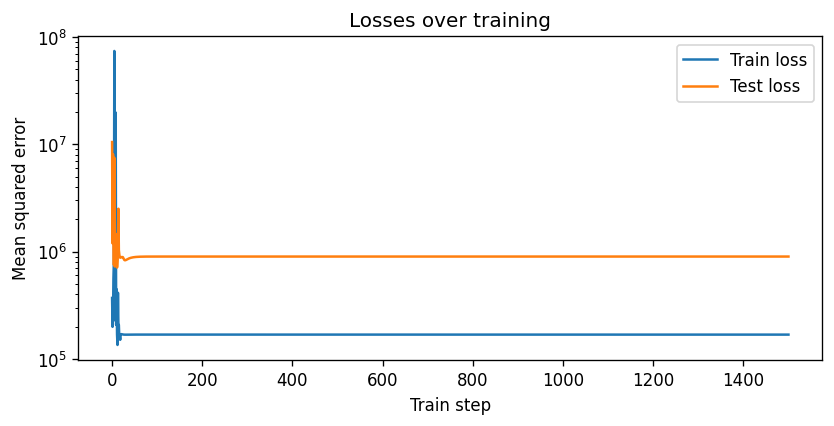

In [19]:
plt.figure(figsize=(8, 3.5), dpi=120)
plt.plot(train_losses, label='Train loss')
plt.plot(test_losses, label='Test loss')
plt.yscale('log')
# plt.ylim(None, 200)
plt.title('Losses over training')
plt.xlabel("Train step") ; plt.ylabel("Mean squared error")
plt.legend() ; plt.show()

## **Step 7: Visualize what the model has learned**

In this section we'll run some basic sanity checks to see whether the model has learned something that resembles the Lagrangian of the system

### **i) Plot predicted vs actual coordinates (we want a 1:1 mapping)**

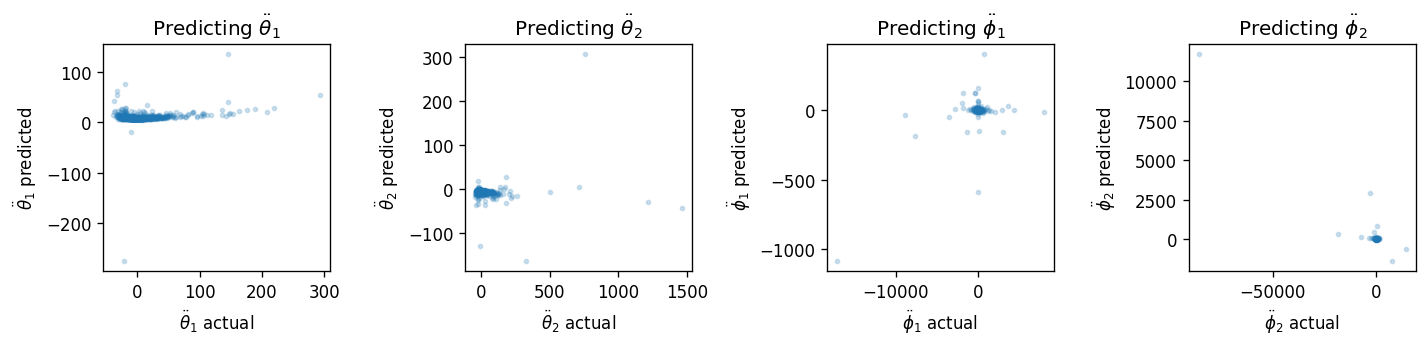

In [20]:
xt_pred = jax.vmap(partial(equation_of_motion, learned_lagrangian(params)))(x_test)

fig, axes = plt.subplots(1, 4, figsize=(12, 3), dpi=120)
axes[0].scatter(xt_test[:, 4], xt_pred[:, 4], s=6, alpha=0.2)
axes[0].set_title(r'Predicting $\ddot{\theta}_1$')
axes[0].set_xlabel(r'$\ddot{\theta}_1$ actual')
axes[0].set_ylabel(r'$\ddot{\theta}_1$ predicted')
axes[1].scatter(xt_test[:, 5], xt_pred[:, 5], s=6, alpha=0.2)
axes[1].set_title(r'Predicting $\ddot{\theta}_2$')
axes[1].set_xlabel(r'$\ddot{\theta}_2$ actual')
axes[1].set_ylabel(r'$\ddot{\theta}_2$ predicted')
axes[2].scatter(xt_test[:, 6], xt_pred[:, 6], s=6, alpha=0.2)
axes[2].set_title(r'Predicting $\ddot{\phi}_1$')
axes[2].set_xlabel(r'$\ddot{\phi}_1$ actual')
axes[2].set_ylabel(r'$\ddot{\phi}_1$ predicted')
axes[3].scatter(xt_test[:, 7], xt_pred[:, 7], s=6, alpha=0.2)
axes[3].set_title(r'Predicting $\ddot{\phi}_2$')
axes[3].set_xlabel(r'$\ddot{\phi}_2$ actual')
axes[3].set_ylabel(r'$\ddot{\phi}_2$ predicted')
plt.tight_layout()

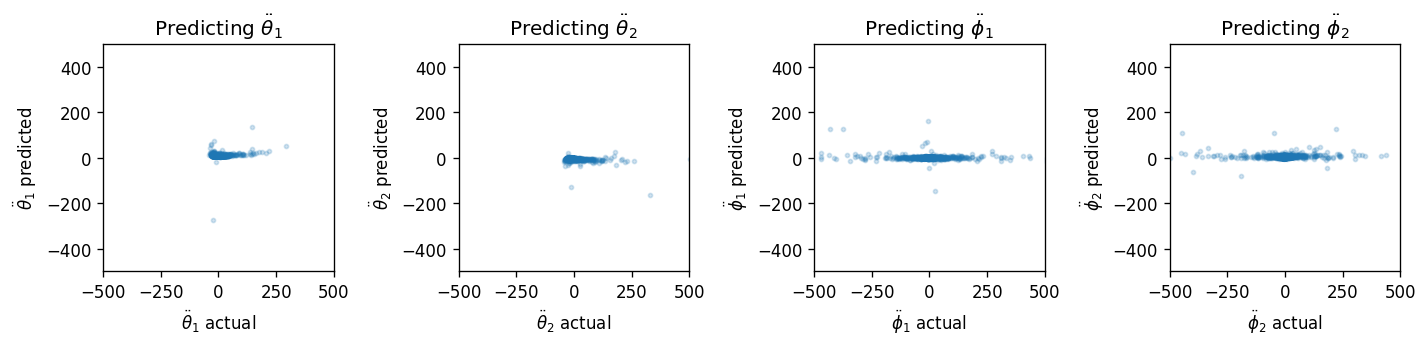

In [21]:
xt_pred = jax.vmap(partial(equation_of_motion, learned_lagrangian(params)))(x_test)

fig, axes = plt.subplots(1, 4, figsize=(12, 3), dpi=120)
axes[0].scatter(xt_test[:, 4], xt_pred[:, 4], s=6, alpha=0.2)
axes[0].set_title(r'Predicting $\ddot{\theta}_1$')
axes[0].set_xlabel(r'$\ddot{\theta}_1$ actual')
axes[0].set_ylabel(r'$\ddot{\theta}_1$ predicted')
axes[0].set_xlim(-500, 500)
axes[0].set_ylim(-500, 500)
axes[1].scatter(xt_test[:, 5], xt_pred[:, 5], s=6, alpha=0.2)
axes[1].set_title(r'Predicting $\ddot{\theta}_2$')
axes[1].set_xlabel(r'$\ddot{\theta}_2$ actual')
axes[1].set_ylabel(r'$\ddot{\theta}_2$ predicted')
axes[1].set_xlim(-500, 500)
axes[1].set_ylim(-500, 500)
axes[2].scatter(xt_test[:, 6], xt_pred[:, 6], s=6, alpha=0.2)
axes[2].set_title(r'Predicting $\ddot{\phi}_1$')
axes[2].set_xlabel(r'$\ddot{\phi}_1$ actual')
axes[2].set_ylabel(r'$\ddot{\phi}_1$ predicted')
axes[2].set_xlim(-500, 500)
axes[2].set_ylim(-500, 500)
axes[3].scatter(xt_test[:, 7], xt_pred[:, 7], s=6, alpha=0.2)
axes[3].set_title(r'Predicting $\ddot{\phi}_2$')
axes[3].set_xlabel(r'$\ddot{\phi}_2$ actual')
axes[3].set_ylabel(r'$\ddot{\phi}_2$ predicted')
axes[3].set_xlim(-500, 500)
axes[3].set_ylim(-500, 500)
plt.tight_layout()

### **ii) Examine the model's performance over the full coordinate space**

In [22]:
# make a meshgrid of possible angles
angle_range = -np.pi + 2 * np.pi * np.arange(100)/100
# x_scanned = np.stack(np.meshgrid(angle_range, angle_range, [0.0], [0.0], indexing='ij'), axis=-1).reshape(-1, 4)

theta1_grid, theta2_grid = np.meshgrid(angle_range, angle_range, indexing='ij')
x_scanned = np.stack([
    theta1_grid.ravel(),
    theta2_grid.ravel(),
    np.full(theta1_grid.size, 3*np.pi/5), # phi1 fixed
    np.full(theta1_grid.size, 3*np.pi/4), # phi2 fixed
    np.zeros(theta1_grid.size), # theta1_dot
    np.zeros(theta1_grid.size), # theta2_dot
    np.zeros(theta1_grid.size), # phi1_dot
    np.zeros(theta1_grid.size), # phi2_dot
], axis=1)

In [23]:
%time xt_actual = jax.vmap(f_analytical)(x_scanned) # actual time derivatives

CPU times: total: 1.53 s
Wall time: 905 ms


In [24]:
%time xt_predicted = jax.vmap(partial(equation_of_motion, learned_lagrangian(params)))(x_scanned) # predicted time derivatives

CPU times: total: 4.64 s
Wall time: 3.23 s


In [25]:
import xarray
dataarray = xarray.DataArray(np.stack([xt_actual.reshape(100, 100, 8),
                                       xt_predicted.reshape(100, 100, 8)]),
                                       dims=['model', 'theta1', 'theta2', 'time_derivative'],
                                       coords={'model': ['actual', 'predicted'], 'theta1': angle_range, 'theta2': angle_range})

Colorscale is $\ddot{\theta}_1$


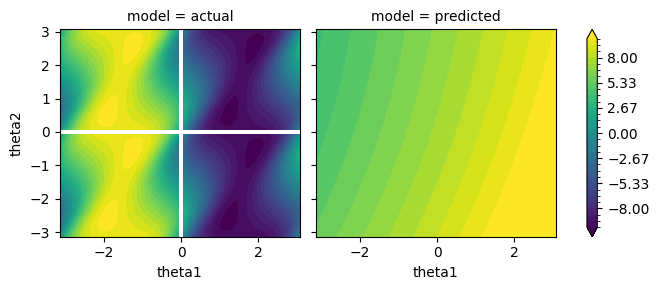

In [26]:
dataarray.isel(time_derivative=4).plot.contourf(levels=31, col='model', x='theta1', y='theta2', vmin=-10, vmax=10)
print(r"Colorscale is $\ddot{\theta}_1$")
plt.show()

Colorscale is $\ddot{\theta}_2$


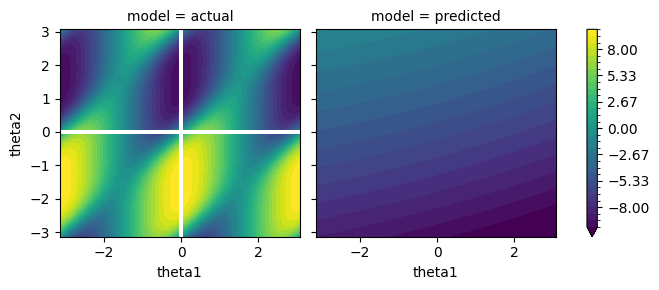

In [27]:
dataarray.isel(time_derivative=5).plot.contourf(levels=31, col='model', x='theta1', y='theta2', vmin=-10, vmax=10)
print(r"Colorscale is $\ddot{\theta}_2$")
plt.show()

Colorscale is $\ddot{\phi}_1$


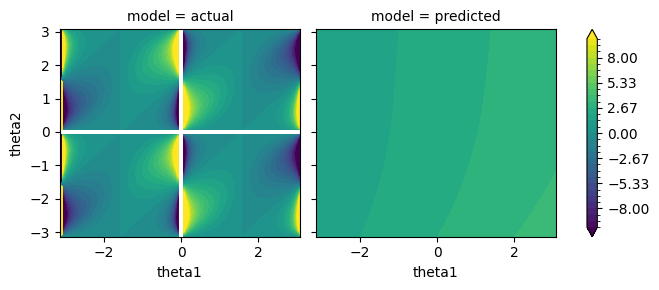

In [28]:
dataarray.isel(time_derivative=6).plot.contourf(levels=31, col='model', x='theta1', y='theta2', vmin=-10, vmax=10)
print(r"Colorscale is $\ddot{\phi}_1$")
plt.show()

Colorscale is $\ddot{\phi}_2$


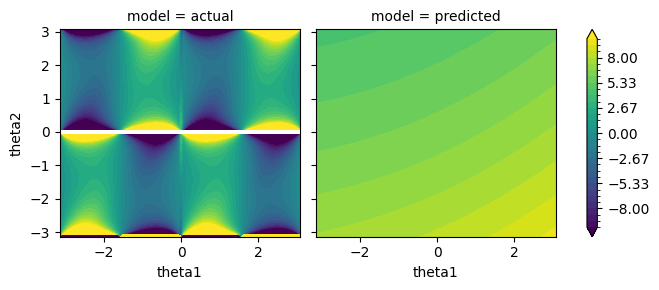

In [29]:
dataarray.isel(time_derivative=7).plot.contourf(levels=31, col='model', x='theta1', y='theta2', vmin=-10, vmax=10)
print(r"Colorscale is $\ddot{\phi}_2$")
plt.show()

## **Step 8: Make predictions with the model**

We should be able to simulate the double spherical pendulum with reasonable degree of accuracy.

In [30]:
# choose an initial state
x1 = np.array([3*np.pi/7, 3*np.pi/6, 3*np.pi/5, 3*np.pi/4, 0.4, 0.3, 0.2, 0.1], dtype=np.float32)

t2 = np.linspace(0, 20, num=301)
%time x1_analytical = jax.device_get(solve_analytical(x1, t2))
noise_coeff_3 = 1e-3
%time x1_perturbed = jax.device_get(solve_analytical(x1 + noise_coeff_3 * noise, t2))
# Cranmer's original t=20 learned rollout was attempted here. 
# For the DSP LNN it became computationally intractable (>25 min)
# and required a kernel restart.
# %time x1_model = jax.device_get(solve_lagrangian(learned_lagrangian(params), x1, t=t2))

t2_model = np.linspace(0, 0.1, num=51)
%time x1_model = jax.device_get(solve_lagrangian(learned_lagrangian(params), x1, t=t2_model))

CPU times: total: 2.16 s
Wall time: 1.22 s
CPU times: total: 594 ms
Wall time: 593 ms


C:\Users\<user>\AppData\Local\Temp\ipykernel_27932\370698877.py:11: DeprecationWarning: backend and device argument on jit is deprecated. You can use `jax.device_put(..., jax.local_devices(backend="cpu")[0])` on the inputs to the jitted function to get the same behavior.
  @partial(jax.jit, backend='cpu')


CPU times: total: 2.39 s
Wall time: 870 ms


ValueError: x and y must have same first dimension, but have shapes (301,) and (51,)

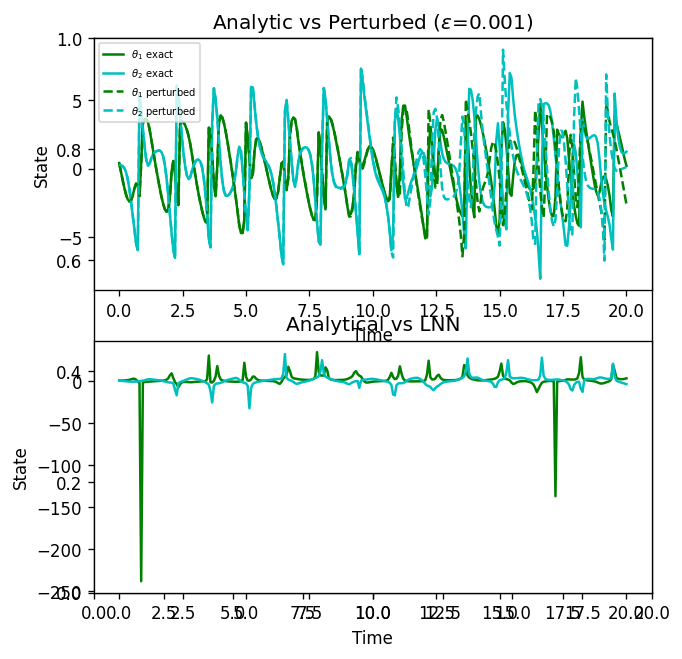

In [31]:
plt.figure(figsize=[6,6], dpi=120) ; plt.xlim(0, 20)
plt.subplot(2,1,1)
plt.title(r"Analytic vs Perturbed ($\epsilon$={})".format(noise_coeff_3))
plt.xlabel("Time") ; plt.ylabel("State")
plt.plot(t2, x1_analytical[:, 4], 'g-', label=r'$\theta_1$ exact')
plt.plot(t2, x1_analytical[:, 5], 'c-', label=r'$\theta_2$ exact')
plt.plot(t2, x1_perturbed[:, 4], 'g--', label=r'$\theta_1$ perturbed')
plt.plot(t2, x1_perturbed[:, 5], 'c--', label=r'$\theta_2$ perturbed')
plt.legend(fontsize=6)

plt.subplot(2,1,2)
plt.title("Analytical vs LNN")
plt.xlabel("Time") ; plt.ylabel("State")
plt.plot(t2, x1_analytical[:, 6], 'g-', label=r'$\theta_1$ exact')
plt.plot(t2, x1_analytical[:, 7], 'c-', label=r'$\theta_2$ exact')
plt.plot(t2, x1_model[:, 6], 'g--', label=r'$\theta_1$ LNN')
plt.plot(t2, x1_model[:, 7], 'c--', label=r'$\theta_2$ LNN')
plt.legend(fontsize=6)

plt.tight_layout() ; plt.show()

## **Step 9: Make videos of the system**

We'll use these to get an intuitive sense of how well our model has learned the dynamics

### **i) First, we need to define functions for plotting the pendulum**

Sam used this scipy tutorial and Stephan Hoyer's wave equation demo for Jax on TPU to write the following code.

Note: The code below has not been adapted to the DSP as the main notebook already covers that. 

In [ ]:
def make_plot(i, cart_coords, R1, R2, max_trail=30, trail_segments=20, r = 0.05):
    # Plot and save an image of the double spherical pendulum configuration for time step i.
    plt.cla()

    x1, y1, z1, x2, y2, z2 = cart_coords
    ax.plot([0, x1[i], x2[i]], [0, y1[i], y2[i]], [0, z1[i], z2[i]], lw=2, c='k') # rods
    c0 = Circle((0, 0), r/2, fc='k', zorder=10) # anchor point
    c1 = Circle((x1[i], y1[i], z1[i]), r, fc='b', ec='b', zorder=10) # mass 1
    c2 = Circle((x2[i], y2[i], z2[i]), r, fc='r', ec='r', zorder=10) # mass 2
    ax.add_patch(c0)
    ax.add_patch(c1)
    ax.add_patch(c2)

    # plot the pendulum trail (ns = number of segments)
    s = max_trail // trail_segments
    for j in range(trail_segments):
        imin = i - (trail_segments-j)*s
        if imin < 0: continue
        imax = imin + s + 1
        alpha = (j/trail_segments)**2 # fade the trail into alpha
        ax.plot(x2[imin:imax], y2[imin:imax], z2[imin:imax], c='r', solid_capstyle='butt',
                lw=2, alpha=alpha)

    # Center the image on the fixed anchor point. Make axes equal. 
    ax.set_xlim(-R1-R2-r, R1+R2+r)
    ax.set_ylim(-R1-R2-r, R1+R2+r)
    ax.set_zlim(-R1-R2-r, R1+R2+r)
    ax.set_aspect('equal', adjustable='box')
    plt.axis('off')
    # plt.savefig('./frames/_img{:04d}.png'.format(i//di), dpi=72)

def radial2cartesian(t1, t2, p1, p2, R1, R2):
    # Convert from radial to Cartesian coordinates.
    x1 = R1 * np.sin(t1) * np.cos(p1)
    y1 = R1 * np.sin(t1) * np.sin(p1)
    z1 = R1 * np.cos(t1)
    x2 = x1 + R2 * np.sin(t2) * np.cos(p2)
    y2 = y1 + R2 * np.sin(t2) * np.sin(p2)
    z2 = z1 + R2 * np.cos(t2)
    return x1, y1, z1, x2, y2, z2

def fig2image(fig):
    fig.canvas.draw()
    data = np.fromstring(fig.canvas.tostring_rgb(), dtype=np.uint8, sep='')
    image = data.reshpae(fig.canvas.get_width_height()[::-1] + (3,))
    return image

### **ii) Next, we'll make a movie of the pendulum's analytic dynamics**

In [ ]:
R1, R2 = 1, 1
theta1, theta2 = x1_analytical[:, 0], x1_analytical[:, 2]
phi1, phi2 = x1_analytical[:, 1], x1_analytical[:, 3]
cart_coords = radial2cartesian(theta1, theta2, phi1, phi2, R1, R2)

fig = plt.figure(figsize=(8.3333, 6.25), dpi=72)
ax = fig.add_subplot(111)

images = []
di = 1
N = 300
for i in range(0, N, di):
    print("{}/{}".format(i // di, N // di), end='\n' if i//di%20==0 else ' ')
    make_plot(i, cart_coords, R1, R2)
    images.append( fig2image(fig) )

In [ ]:
import importlib
importlib.reload(proglog)
print("True (analytical) dynamics of the double spherical pendulum:")
proglog.default_bar_logger = partial(proglog.default_bar_logger, None)
ImageSequenceClip(images, fps=25).ipython_display()

### **ii) Now let's visualize the LNN's dynamics**

In [ ]:
R1, R2 = 1, 1
theta1, theta2 = x1_model[:, 0], x1_model[:, 2]
phi1, phi2 = x1_model[:, 1], x1_model[:, 3]

fig = plt.figure(figsize=(8.3333, 6.25), dpi=72)
ax = fig.add_subplot(111)

images = []
di = i
N = 300
for i in range(0, N, di):
    print("{}/{}".format(i // di, N // di), end='\n' if i//di%20==0 else ' ')
    make_plot(i, cart_coords, R1, R2)
    images.append( fig2image(fig) )

In [ ]:
import importlib
importlib.reload(proglog)
print("LNN-predicted dynamics fo the double spherical pendulum:")
proglog.default_bar_logger = partial(proglog.default_bar_logger, None)
ImageSequenceClip(images, fps=25).ipython_display()

In [ ]:
def save_movie(images, path, duration=100, loop=0, **kwargs):
    images[0].save(path, save_all=True, append_images=images[1:],
                   duration=duration, loop=loop, **kwargs)

# Save GIF.
PIL_images = [Image.fromarray(im, mode='RGB') for im in images]
save_movie(PIL_images, 'double_spherical_pend_lnn.gif')
# The movie sometimes takes a second before showing up in the file system.
import time ; time.sleep(1)

# Download animation.
files.download('double_pend_lnn.gif')

## **Step 10: Conclusions** 

The LNN was successfully adapted from Cranmer et al. to the double spherical pendulum while perserving the original architecture, Euler-Lagrange formulation, optimization procedure, and pseudoinverse-based calculation of the generalized accelerations. The principal modification was extending the state from the planar double pendulum representation to the four generalized coordinates

$$ \vec{q} = (\theta_1, \theta_2, \phi_1, \phi_2), $$

giving an eight-dimensional state $(\vec{q}, \dot{\vec{q}})$. A genuinely three-dimensional training trajectory was generated over $0 \leq t \leq 50$ using the independently derived analytical equations of motion.  

Despite being trained directly on state derivatives, the LNN did not accurately reproduce the generalized acceleration field. The final acceleration errors remained comparable to the characteristic magnitudes of the target accelerations, indicating that the network learned relatively little useful acceleration information. The largest errors were concentrated in states approaching the polar regions of the spherical coordinate system.  

This behavior was strongly associated with the conditioning of the exact Lagrangian velocity Hessian. Across the training trajectory, the median condition number was approximately $10.7$, while states producing the largest prediction errors reached condition numbers of order $10^3$. The logarithm of the Hessian condition number was strongly correlated with both the magnitude of the true generalized acceleration and the LNN prediction error, with correlation coefficients of approximately $0.85$. In addition, a coordinate-space scan showed that the analytical generalized-coordinate equations became nonfinite exactly along the grid lines $\theta_1 = 0$ and $\theta_2 = 0$. Of the $10,000$ sampled configurations, $199$ were nonfinite, corresponding exactly to the union of these two polar lines. Near the poles, finite generalized accelerations reached magnitudes of order $10^6$.  

These results demonstrate an important limitation of the generalized coordinate representation. At a pole, the azimuthal coordinate $\phi_i$ becomes undefined even though the Cartesian position and physical motion of the corresponding pendulum remain well defined. Consequently, the velocity Hessian associated with the spherical coordinate Lagrangian becomes increasingly ill-conditioned near these coordinate singularities. The LNN is therefore asked to learn a generalized coordinate vector field containing extremely large derivatives and undefined limiting behavior in regions where the underlying Cartesian dynamics remain regular.  

These results motivate replacing the minimal spherical coordinate representation with a redundant Cartesian representation in which the physical rod lengths are enforced explicitly as holonomic constraints. This provides the motivation for the constrained Lagrangian neural network approach considered next. 

In [35]:
# ===============================================
# TEST-ONLY — diagnose final learned vector field
# ===============================================

f_learned = partial(
    equation_of_motion,
    learned_lagrangian(params)
)

pred_train = jax.device_get(
    jax.vmap(f_learned)(x_train)
)

pred_test = jax.device_get(
    jax.vmap(f_learned)(x_test)
)

train_component_mse = np.mean(
    (pred_train - np.asarray(xt_train))**2,
    axis=0
)

test_component_mse = np.mean(
    (pred_test - np.asarray(xt_test))**2,
    axis=0
)

names = [
    "theta1_dot",
    "theta2_dot",
    "phi1_dot",
    "phi2_dot",
    "theta1_ddot",
    "theta2_ddot",
    "phi1_ddot",
    "phi2_ddot"
]

for name, tr, te in zip(
    names,
    train_component_mse,
    test_component_mse
):
    print(
        f"{name:12s}: "
        f"train={tr:.6e}, "
        f"test={te:.6e}"
    )

# ==========================================
# DIAGNOSTIC — acceleration-error quantities
# ==========================================

x_np = np.asarray(x_train)
xt_np = np.asarray(xt_train)
pred_np = np.asarray(pred_train)

# True and predicted generalized accelerations
# state derivative ordering:
# [theta1_dot, theta2_dot, phi1_dot, phi2_dot,
#  theta1_ddot, theta2_ddot, phi1_ddot, phi2_ddot]

target_acc = xt_np[:, 4:]
pred_acc   = pred_np[:, 4:]

# Magnitude of true generalized acceleration
target_acc_mag = np.linalg.norm(
    target_acc,
    axis=1
)

# Magnitude of LNN acceleration prediction error
error_acc_mag = np.linalg.norm(
    pred_acc - target_acc,
    axis=1
)

# Distance from the nearest spherical-coordinate pole
pole_measure = np.minimum(
    np.abs(np.sin(x_np[:, 0])),
    np.abs(np.sin(x_np[:, 1]))
)

# ==============================================================
# DIAGNOSTIC — inspect worst target accelerations and LNN errors
# ==============================================================

idx_target = np.argsort(target_acc_mag)[-10:][::-1]
idx_error  = np.argsort(error_acc_mag)[-10:][::-1]

print("=== Largest TRUE acceleration magnitudes ===")
for i in idx_target:
    print(
        f"i={i:4d}  "
        f"theta1={x_np[i,0]: .5f}  "
        f"theta2={x_np[i,1]: .5f}  "
        f"pole={pole_measure[i]:.6f}  "
        f"|a_true|={target_acc_mag[i]:.3f}  "
        f"|error|={error_acc_mag[i]:.3f}"
    )

print("\n=== Largest LNN acceleration errors ===")
for i in idx_error:
    print(
        f"i={i:4d}  "
        f"theta1={x_np[i,0]: .5f}  "
        f"theta2={x_np[i,1]: .5f}  "
        f"pole={pole_measure[i]:.6f}  "
        f"|a_true|={target_acc_mag[i]:.3f}  "
        f"|error|={error_acc_mag[i]:.3f}"
    )

# DIAGNOSTIC — exact Lagrangian Hessian conditioning
# =========================================
# DIAGNOSTIC — bind DSP physical parameters
# =========================================
L_exact = partial(
    lagrangian,
    m1=1.,
    m2=1.,
    R1=1.,
    R2=1.,
    g=9.8
)

H_exact_fn = jax.jit(
    jax.hessian(L_exact, 1)
)

H_exact = jax.device_get(
    jax.vmap(H_exact_fn)(
        x_train[:, :4],
        x_train[:, 4:]
    )
)

svals = np.linalg.svd(H_exact, compute_uv=False)

sigma_max = svals[:, 0]
sigma_min = svals[:, -1]
cond_exact = sigma_max / sigma_min

print("Exact Hessian condition number:")
print("min   =", np.min(cond_exact))
print("median=", np.median(cond_exact))
print("mean  =", np.mean(cond_exact))
print("max   =", np.max(cond_exact))

print("\nWorst-error states:")
for i in idx_error:
    print(
        f"i={i:4d}  "
        f"pole={pole_measure[i]:.6f}  "
        f"sigma_min={sigma_min[i]:.6e}  "
        f"cond={cond_exact[i]:.6e}  "
        f"|a_true|={target_acc_mag[i]:.3f}  "
        f"|error|={error_acc_mag[i]:.3f}"
    )

# =======================================
# DIAGNOSTIC — dataset-wide relationships
# =======================================

print(
    "corr(pole, log10(cond)) =",
    np.corrcoef(
        pole_measure,
        np.log10(cond_exact)
    )[0, 1]
)

print(
    "corr(log10(cond), log10(|a_true|)) =",
    np.corrcoef(
        np.log10(cond_exact),
        np.log10(target_acc_mag)
    )[0, 1]
)

print(
    "corr(log10(cond), log10(|error|)) =",
    np.corrcoef(
        np.log10(cond_exact),
        np.log10(error_acc_mag)
    )[0, 1]
)

# DIAGNOSTIC — count nonfinite exact configurations
actual = jax.device_get(jax.vmap(f_analytical)(jnp.asarray(x_scanned)))

finite = np.all(np.isfinite(actual), axis=-1)

print("finite:", np.count_nonzero(finite))
print("nonfinite:", np.count_nonzero(~finite))

theta1_dot  : train=0.000000e+00, test=0.000000e+00
theta2_dot  : train=0.000000e+00, test=0.000000e+00
phi1_dot    : train=0.000000e+00, test=0.000000e+00
phi2_dot    : train=0.000000e+00, test=0.000000e+00
theta1_ddot : train=1.346737e+03, test=7.405121e+02
theta2_ddot : train=1.311908e+03, test=4.186083e+03
phi1_ddot   : train=8.897439e+05, test=3.762107e+05
phi2_ddot   : train=4.548138e+05, test=6.816102e+06
=== Largest TRUE acceleration magnitudes ===
i= 236  theta1= 0.03779  theta2= 0.48712  pole=0.037780  |a_true|=19685.777  |error|=21932.357
i= 526  theta1= 0.02199  theta2= 1.13349  pole=0.021987  |a_true|=18737.635  |error|=19654.590
i=  22  theta1= 0.25561  theta2= 0.04458  pole=0.044570  |a_true|=15078.538  |error|=15485.828
i=1454  theta1= 0.03514  theta2= 1.87686  pole=0.035131  |a_true|=14510.108  |error|=13980.427
i= 890  theta1= 0.60936  theta2= 0.05463  pole=0.054605  |a_true|=14250.691  |error|=14270.581
i=  66  theta1= 0.30927  theta2= 0.06833  pole=0.068275  |a_true